# Logistic Regression: Diabetes Screening

## Interactive Visualization of Gradient Descent and Decision Boundaries

Welcome to this comprehensive tutorial on **Logistic Regression** using a clinical screening problem. You'll see how the algorithm iteratively adjusts the decision boundary to separate patients who screen positive for type 2 diabetes from those who do not.

## What You'll Learn
- **Visual gradient descent**: Watch the decision boundary shift in real-time
- **Clinical classification**: Diabetic vs. non-diabetic screening from two routine measurements
- **Mathematical intuition**: Sigmoid function and log loss with clear explanations
- **Interactive exploration**: Adjust parameters and see immediate effects
- **Model interpretation**: Understand probability contours and confidence regions
- **Practical applications**: When and why to use logistic regression on clinical data

> **A note on the data.** Every patient in this notebook is simulated from
> published reference ranges. No real or identifiable patient data is used.

---


## 1. Introduction & Setup

We'll build a classifier to separate patients who screen **positive for type 2 diabetes** from those who screen **negative**, using two measurements that are routinely collected at a screening visit:
- **Fasting plasma glucose** (mmol/L): the single most informative screening test
- **Body mass index, BMI** (kg/m²): the strongest modifiable risk factor

This is a realistic screening problem where the decision boundary represents the trade-off the clinic makes between calling a patient in for a confirmatory test and sending them home.


In [1]:
# Essential imports for clinical logistic regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, clear_output
import time

# Machine learning imports
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider

# Styling for professional clinical presentations
plt.style.use('default')
sns.set_palette(['#1f77b4', '#ff7f0e'])  # Blue for No Diabetes, Orange for Diabetes
np.random.seed(42)

print("🩺 Diabetes Screening Classification: Logistic Regression Ready")
print("   Demonstrating gradient descent for diabetic vs. non-diabetic screening")


🩺 Diabetes Screening Classification: Logistic Regression Ready
   Demonstrating gradient descent for diabetic vs. non-diabetic screening


## 2. Screening Dataset Generation

Let's create a simulated screening cohort using published reference ranges:

**Patients who screen negative:**
- Fasting glucose clustered around 5.2 mmol/L (normal range is roughly 3.9–5.5)
- BMI clustered around 25 kg/m²

**Patients who screen positive:**
- Fasting glucose clustered around 8.5 mmol/L (the diagnostic threshold is 7.0)
- BMI clustered around 32 kg/m²

The two groups deliberately **overlap**: plenty of people with a raised BMI have
perfectly normal glucose, and some lean patients are diabetic. That overlap is
exactly what makes the decision boundary interesting — and it is what real
screening data looks like.

*All values below are simulated. No real or identifiable patient data is used.*


In [2]:
def generate_diabetes_screening_data(n_samples=300):
    """Generate a simulated diabetes screening cohort.

    Features:
    - fasting_glucose (mmol/L): fasting plasma glucose
    - bmi (kg/m^2): body mass index

    Target: diabetes (0 = screens negative, 1 = screens positive)

    Values are simulated from published reference ranges. No real or
    identifiable patient data is used.
    """
    np.random.seed(42)

    # Patients who screen negative (class 0)
    n_neg = n_samples // 2
    neg_glucose = np.random.normal(5.2, 0.55, n_neg)   # normal fasting glucose
    neg_bmi = np.random.normal(25.0, 3.5, n_neg)       # around the overweight cut-off

    # Adiposity raises fasting glucose even in non-diabetics
    neg_glucose += 0.05 * (neg_bmi - 25.0)

    # Patients who screen positive (class 1)
    n_pos = n_samples - n_neg
    pos_glucose = np.random.normal(8.5, 1.6, n_pos)    # well above the 7.0 threshold
    pos_bmi = np.random.normal(32.0, 4.5, n_pos)       # obese range

    # Same direction of effect, a little stronger in the diabetic group
    pos_glucose += 0.07 * (pos_bmi - 32.0)

    # Combine
    glucose = np.concatenate([neg_glucose, pos_glucose])
    bmi = np.concatenate([neg_bmi, pos_bmi])
    diabetes = np.concatenate([np.zeros(n_neg), np.ones(n_pos)])

    # Keep every value inside a physiologically possible range
    glucose = np.clip(glucose, 3.5, 16.0)
    bmi = np.clip(bmi, 16.0, 50.0)

    data = pd.DataFrame({
        'bmi': bmi,
        'fasting_glucose': glucose,
        'diabetes': diabetes,
        'diagnosis': ['No Diabetes' if s == 0 else 'Diabetes' for s in diabetes]
    })

    return data.reset_index(drop=True)

# Generate our screening cohort
clinical_data = generate_diabetes_screening_data(300)

print("🩺 Diabetes Screening Dataset Generated (simulated, no real patient data)")
print(f"   Total patients: {len(clinical_data)}")
print(f"   Class distribution: {clinical_data['diagnosis'].value_counts().to_dict()}")

# Display basic statistics
print("\n📊 Dataset Summary:")
print(clinical_data.groupby('diagnosis')[['bmi', 'fasting_glucose']].describe().round(2))


🩺 Diabetes Screening Dataset Generated (simulated, no real patient data)
   Total patients: 300
   Class distribution: {'No Diabetes': 150, 'Diabetes': 150}

📊 Dataset Summary:
               bmi                                                  \
             count   mean   std    min    25%    50%    75%    max   
diagnosis                                                            
Diabetes     150.0  31.56  4.37  20.88  28.57  31.36  34.41  45.85   
No Diabetes  150.0  25.26  3.53  16.00  22.59  25.50  27.36  38.48   

            fasting_glucose                                            
                      count  mean   std   min  25%   50%   75%    max  
diagnosis                                                              
Diabetes              150.0  8.56  1.54  5.08  7.4  8.46  9.63  12.28  
No Diabetes           150.0  5.17  0.54  3.68  4.8  5.17  5.52   6.49  


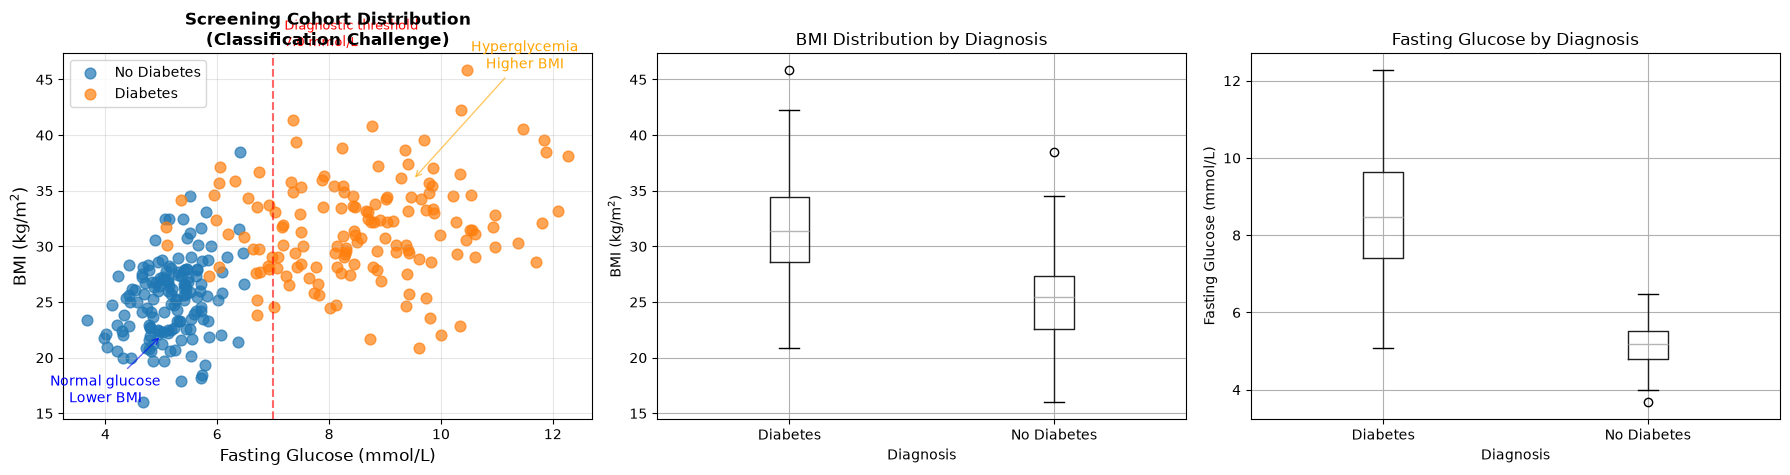

🔍 Key Observations:
   • Screens negative (blue): normal fasting glucose, lower BMI
   • Screens positive (orange): raised fasting glucose, higher BMI
   • The groups overlap - this is where ML classification helps!
   • Perfect scenario for a logistic regression decision boundary


In [3]:
# Visualize the screening cohort
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot of the two features
colors = ['#1f77b4', '#ff7f0e']  # Blue for No Diabetes, Orange for Diabetes
class_names = ['No Diabetes', 'Diabetes']

for i, label in enumerate(class_names):
    subset = clinical_data[clinical_data['diagnosis'] == label]
    axes[0].scatter(subset['fasting_glucose'], subset['bmi'],
                   c=colors[i], label=label, alpha=0.7, s=60)

axes[0].axvline(x=7.0, color='red', linestyle='--', alpha=0.6)
axes[0].set_xlabel('Fasting Glucose (mmol/L)', fontsize=12)
axes[0].set_ylabel('BMI (kg/m$^2$)', fontsize=12)
axes[0].set_title('Screening Cohort Distribution\n(Classification Challenge)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Add clinical context annotations
axes[0].annotate('Normal glucose\nLower BMI', xy=(5.0, 22), xytext=(4.0, 16),
                arrowprops=dict(arrowstyle='->', color='blue', alpha=0.6),
                fontsize=10, ha='center', color='blue')
axes[0].annotate('Hyperglycemia\nHigher BMI', xy=(9.5, 36), xytext=(11.5, 46),
                arrowprops=dict(arrowstyle='->', color='orange', alpha=0.6),
                fontsize=10, ha='center', color='orange')
axes[0].annotate('Diagnostic threshold\n7.0 mmol/L', xy=(7.0, 47), xytext=(7.2, 48),
                fontsize=9, color='red')

# Distribution of BMI by diagnosis
clinical_data.boxplot(column='bmi', by='diagnosis', ax=axes[1])
axes[1].set_title('BMI Distribution by Diagnosis')
axes[1].set_xlabel('Diagnosis')
axes[1].set_ylabel('BMI (kg/m$^2$)')
plt.suptitle('')  # Remove automatic title from boxplot

# Distribution of fasting glucose by diagnosis
clinical_data.boxplot(column='fasting_glucose', by='diagnosis', ax=axes[2])
axes[2].set_title('Fasting Glucose by Diagnosis')
axes[2].set_xlabel('Diagnosis')
axes[2].set_ylabel('Fasting Glucose (mmol/L)')
plt.suptitle('')  # Remove automatic title from boxplot

plt.tight_layout()
plt.show()

print("🔍 Key Observations:")
print("   • Screens negative (blue): normal fasting glucose, lower BMI")
print("   • Screens positive (orange): raised fasting glucose, higher BMI")
print("   • The groups overlap - this is where ML classification helps!")
print("   • Perfect scenario for a logistic regression decision boundary")


## 3. Mathematical Foundation: Sigmoid Function

Before diving into the training visualization, let's understand the core of logistic regression:

**The Sigmoid Function**: σ(z) = 1 / (1 + e^(-z))

This function maps any real number to a probability between 0 and 1, making it perfect for binary classification.

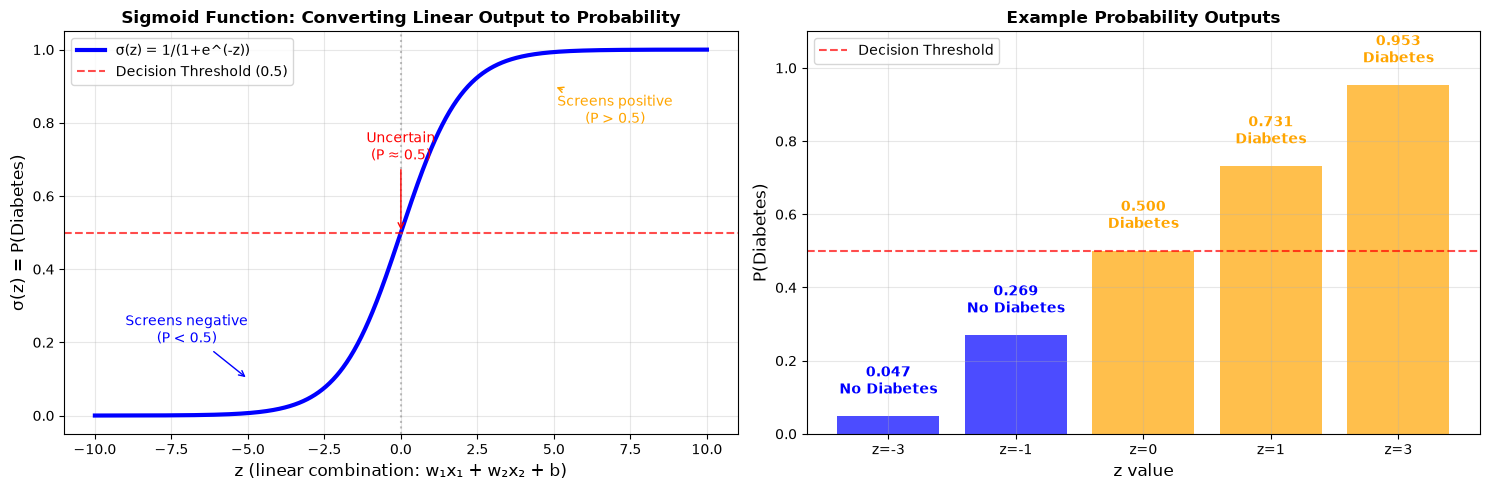

🧮 Sigmoid Function Key Points:
   • Maps any real number z to probability [0, 1]
   • z = w₁×(glucose) + w₂×(BMI) + bias
   • Output > 0.5 → Diabetes, Output < 0.5 → No Diabetes
   • S-shaped curve provides smooth probability transitions


In [4]:
def sigmoid(z):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))  # Clip to prevent overflow

# Demonstrate sigmoid function
z_values = np.linspace(-10, 10, 1000)
sigmoid_values = sigmoid(z_values)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot sigmoid function
axes[0].plot(z_values, sigmoid_values, 'b-', linewidth=3, label='σ(z) = 1/(1+e^(-z))')
axes[0].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Decision Threshold (0.5)')
axes[0].axvline(x=0, color='gray', linestyle=':', alpha=0.5)
axes[0].set_xlabel('z (linear combination: w₁x₁ + w₂x₂ + b)', fontsize=12)
axes[0].set_ylabel('σ(z) = P(Diabetes)', fontsize=12)
axes[0].set_title('Sigmoid Function: Converting Linear Output to Probability', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Add clinical context annotations
axes[0].annotate('Screens negative\n(P < 0.5)', xy=(-5, 0.1), xytext=(-7, 0.2),
                arrowprops=dict(arrowstyle='->', color='blue'),
                fontsize=10, ha='center', color='blue')
axes[0].annotate('Screens positive\n(P > 0.5)', xy=(5, 0.9), xytext=(7, 0.8),
                arrowprops=dict(arrowstyle='->', color='orange'),
                fontsize=10, ha='center', color='orange')
axes[0].annotate('Uncertain\n(P ≈ 0.5)', xy=(0, 0.5), xytext=(0, 0.7),
                arrowprops=dict(arrowstyle='->', color='red'),
                fontsize=10, ha='center', color='red')

# Show how different z values map to probabilities
z_examples = [-3, -1, 0, 1, 3]
prob_examples = sigmoid(np.array(z_examples))
label_examples = ['No Diabetes' if p < 0.5 else 'Diabetes' for p in prob_examples]
colors_examples = ['blue' if p < 0.5 else 'orange' for p in prob_examples]

axes[1].bar(range(len(z_examples)), prob_examples, color=colors_examples, alpha=0.7)
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Decision Threshold')
axes[1].set_xlabel('z value', fontsize=12)
axes[1].set_ylabel('P(Diabetes)', fontsize=12)
axes[1].set_title('Example Probability Outputs', fontweight='bold')
axes[1].set_xticks(range(len(z_examples)))
axes[1].set_xticklabels([f'z={z}' for z in z_examples])

# Add probability values on top of bars
for i, (z, prob, label, color) in enumerate(zip(z_examples, prob_examples, label_examples, colors_examples)):
    axes[1].text(i, prob + 0.05, f'{prob:.3f}\n{label}', 
                ha='center', va='bottom', fontweight='bold', color=color)

axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

print("🧮 Sigmoid Function Key Points:")
print("   • Maps any real number z to probability [0, 1]")
print("   • z = w₁×(glucose) + w₂×(BMI) + bias")
print("   • Output > 0.5 → Diabetes, Output < 0.5 → No Diabetes")
print("   • S-shaped curve provides smooth probability transitions")

## 4. Implementing Logistic Regression from Scratch

Now let's implement logistic regression with gradient descent to see exactly how the decision boundary shifts during training.

In [5]:
class ClinicalLogisticRegression:
    """Logistic Regression implementation for clinical binary screening."""
    
    def __init__(self, learning_rate=0.01, max_iterations=1000):
        self.learning_rate = learning_rate
        self.max_iterations = max_iterations
        self.weights = None
        self.bias = None
        self.costs = []
        
    def sigmoid(self, z):
        """Sigmoid activation function with overflow protection."""
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    
    def initialize_parameters(self, n_features):
        """Initialize weights and bias."""
        self.weights = np.random.normal(0, 0.1, n_features)
        self.bias = 0.0
    
    def forward_propagation(self, X):
        """Forward pass: compute predictions."""
        z = np.dot(X, self.weights) + self.bias
        predictions = self.sigmoid(z)
        return predictions
    
    def compute_cost(self, y_true, y_pred):
        """Compute logistic regression cost (log loss)."""
        m = len(y_true)
        # Add small epsilon to prevent log(0)
        epsilon = 1e-15
        y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
        cost = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
        return cost
    
    def backward_propagation(self, X, y_true, y_pred):
        """Backward pass: compute gradients."""
        m = len(y_true)
        
        # Compute gradients
        dw = np.dot(X.T, (y_pred - y_true)) / m
        db = np.mean(y_pred - y_true)
        
        return dw, db
    
    def update_parameters(self, dw, db):
        """Update weights and bias using gradient descent."""
        self.weights -= self.learning_rate * dw
        self.bias -= self.learning_rate * db
    
    def fit(self, X, y):
        """Train the logistic regression model."""
        # Initialize parameters
        self.initialize_parameters(X.shape[1])
        self.costs = []
        
        # Training loop
        for i in range(self.max_iterations):
            # Forward propagation
            y_pred = self.forward_propagation(X)
            
            # Compute cost
            cost = self.compute_cost(y, y_pred)
            self.costs.append(cost)
            
            # Backward propagation
            dw, db = self.backward_propagation(X, y, y_pred)
            
            # Update parameters
            self.update_parameters(dw, db)
    
    def predict_proba(self, X):
        """Predict class probabilities."""
        return self.forward_propagation(X)
    
    def predict(self, X):
        """Make binary predictions."""
        probabilities = self.predict_proba(X)
        return (probabilities > 0.5).astype(int)
    
    def get_decision_boundary_line(self, x_range):
        """Get y-coordinates for decision boundary line."""
        # Decision boundary: w1*x1 + w2*x2 + b = 0
        # Solve for x2: x2 = -(w1*x1 + b) / w2
        if abs(self.weights[1]) > 1e-10:  # Avoid division by zero
            y_boundary = -(self.weights[0] * x_range + self.bias) / self.weights[1]
            return y_boundary
        else:
            # Vertical line case
            return None

print("🤖 Custom Clinical Logistic Regression Implementation Ready")
print("   Features: Visual gradient descent, decision boundary tracking")

🤖 Custom Clinical Logistic Regression Implementation Ready
   Features: Visual gradient descent, decision boundary tracking


## 5. Interactive Training Visualization

Now for the exciting part! Watch as the decision boundary iteratively shifts to find the optimal separation between No Diabetes and Diabetes.

In [6]:
def train_with_visualization(clinical_data, learning_rate=0.05, max_iterations=200, update_frequency=5):
    """Train logistic regression with real-time visualization of decision boundary."""
    
    # Prepare data
    X = clinical_data[['fasting_glucose', 'bmi']].values
    y = clinical_data['diabetes'].values
    
    # Standardize features for better convergence
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Initialize model
    model = ClinicalLogisticRegression(learning_rate=learning_rate, max_iterations=max_iterations)
    model.initialize_parameters(X_scaled.shape[1])
    
    # Training loop with visualization
    costs = []
    
    print("🚀 Starting Interactive Training Visualization...")
    print("   Watch the decision boundary shift to optimize classification!")
    
    for iteration in range(max_iterations):
        # Forward propagation
        y_pred = model.forward_propagation(X_scaled)
        
        # Compute cost
        cost = model.compute_cost(y, y_pred)
        costs.append(cost)
        
        # Backward propagation and parameter update
        dw, db = model.backward_propagation(X_scaled, y, y_pred)
        model.update_parameters(dw, db)
        
        # Visualization update
        if iteration == 0 or (iteration + 1) % update_frequency == 0 or iteration == max_iterations - 1:
            clear_output(wait=True)
            
            # Create visualization
            fig = make_subplots(
                rows=2, cols=2,
                column_widths=[0.7, 0.3],
                row_heights=[0.7, 0.3],
                subplot_titles=(
                    'Diabetes Screening (Decision Boundary Evolution)',
                    'Model Parameters',
                    '',
                    'Training Loss (Log Loss)'
                ),
                specs=[[{"rowspan": 2}, {}], [None, {}]]
            )
            
            # Main plot: Data points and decision boundary
            colors = ['#1f77b4', '#ff7f0e']
            class_names = ['No Diabetes', 'Diabetes']
            
            for i, label in enumerate(['No Diabetes', 'Diabetes']):
                subset = clinical_data[clinical_data['diagnosis'] == label]
                
                # Get predictions for coloring (correct vs incorrect)
                subset_indices = clinical_data[clinical_data['diagnosis'] == label].index
                subset_predictions = model.predict(X_scaled[subset_indices])
                subset_actual = y[subset_indices]
                
                # Correctly classified points
                correct_mask = subset_predictions == subset_actual
                if np.any(correct_mask):
                    correct_subset = subset[correct_mask]
                    fig.add_trace(
                        go.Scatter(
                            x=correct_subset['fasting_glucose'],
                            y=correct_subset['bmi'],
                            mode='markers',
                            name=f'{label} (Correct)',
                            marker=dict(color=colors[i], size=8, symbol='circle'),
                            showlegend=True
                        ), row=1, col=1
                    )
                
                # Incorrectly classified points
                incorrect_mask = ~correct_mask
                if np.any(incorrect_mask):
                    incorrect_subset = subset[incorrect_mask]
                    fig.add_trace(
                        go.Scatter(
                            x=incorrect_subset['fasting_glucose'],
                            y=incorrect_subset['bmi'],
                            mode='markers',
                            name=f'{label} (Incorrect)',
                            marker=dict(color=colors[i], size=10, symbol='x', 
                                      line=dict(color='red', width=2)),
                            showlegend=True
                        ), row=1, col=1
                    )
            
            # Decision boundary
            glucose_range = np.linspace(clinical_data['fasting_glucose'].min() - 0.5, 
                                   clinical_data['fasting_glucose'].max() + 0.5, 100)
            bmi_range = np.linspace(clinical_data['bmi'].min() - 3,
                                     clinical_data['bmi'].max() + 3, 100)
            
            # Transform to scaled space and get boundary
            glucose_scaled = (glucose_range - scaler.mean_[0]) / scaler.scale_[0]
            
            if abs(model.weights[1]) > 1e-10:
                bmi_scaled = -(model.weights[0] * glucose_scaled + model.bias) / model.weights[1]
                bmi_boundary = bmi_scaled * scaler.scale_[1] + scaler.mean_[1]
                
                # Only plot reasonable boundary points
                valid_mask = (bmi_boundary >= clinical_data['bmi'].min() - 6) & \
                            (bmi_boundary <= clinical_data['bmi'].max() + 6)
                
                if np.any(valid_mask):
                    fig.add_trace(
                        go.Scatter(
                            x=glucose_range[valid_mask],
                            y=bmi_boundary[valid_mask],
                            mode='lines',
                            name='Decision Boundary',
                            line=dict(color='red', width=3, dash='dash'),
                            showlegend=True
                        ), row=1, col=1
                    )
            
            # Parameter visualization
            param_names = ['Weight 1\n(Glucose)', 'Weight 2\n(BMI)', 'Bias']
            param_values = [model.weights[0], model.weights[1], model.bias]
            param_colors = ['red' if v < 0 else 'green' for v in param_values]
            
            fig.add_trace(
                go.Bar(
                    x=param_names,
                    y=param_values,
                    marker_color=param_colors,
                    name='Parameters',
                    showlegend=False
                ), row=1, col=2
            )
            
            # Loss curve
            fig.add_trace(
                go.Scatter(
                    x=list(range(len(costs))),
                    y=costs,
                    mode='lines',
                    name='Training Loss',
                    line=dict(color='blue', width=2),
                    showlegend=False
                ), row=2, col=2
            )
            
            # Update layout
            fig.update_layout(
                title=f'Iteration {iteration + 1}/{max_iterations} | Loss: {cost:.4f} | LR: {learning_rate}',
                width=1400,
                height=800,
                showlegend=True
            )
            
            # Update axes labels
            fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=1)
            fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=1)
            fig.update_xaxes(title_text="Parameter", row=1, col=2)
            fig.update_yaxes(title_text="Value", row=1, col=2)
            fig.update_xaxes(title_text="Iteration", row=2, col=2)
            fig.update_yaxes(title_text="Loss", row=2, col=2)
            
            fig.show()
            
            # Calculate and display accuracy
            predictions = model.predict(X_scaled)
            accuracy = accuracy_score(y, predictions)
            
            print(f"Iteration {iteration + 1:3d}: Loss = {cost:.6f}, Accuracy = {accuracy:.3f}")
            
            # Add small delay for visualization
            if iteration < max_iterations - 1:
                time.sleep(0.1)
    
    print("\n🎯 Training Complete!")
    print(f"   Final Loss: {costs[-1]:.6f}")
    print(f"   Final Accuracy: {accuracy:.3f}")
    print(f"   Decision boundary learned to separate diabetic from non-diabetic patients!")
    
    return model, scaler, costs

# Run the interactive training
model, scaler, costs = train_with_visualization(clinical_data, learning_rate=0.1, max_iterations=100, update_frequency=5)

Iteration 100: Loss = 0.220581, Accuracy = 0.953

🎯 Training Complete!
   Final Loss: 0.220581
   Final Accuracy: 0.953
   Decision boundary learned to separate diabetic from non-diabetic patients!


## 6. Interactive Parameter Exploration

Now let's explore how different hyperparameters affect the learning process and decision boundary.

In [7]:
def interactive_parameter_demo(learning_rate=0.05, max_iterations=150):
    """Interactive demo showing effect of different parameters."""
    
    # Prepare data
    X = clinical_data[['fasting_glucose', 'bmi']].values
    y = clinical_data['diabetes'].values
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Train model
    model = ClinicalLogisticRegression(learning_rate=learning_rate, max_iterations=max_iterations)
    model.fit(X_scaled, y)
    
    # Final predictions
    predictions = model.predict(X_scaled)
    probabilities = model.predict_proba(X_scaled)
    accuracy = accuracy_score(y, predictions)
    
    # Create comprehensive visualization
    fig = make_subplots(
        rows=2, cols=2,
        subplot_titles=(
            'Final Classification Results',
            'Probability Contours',
            'Training Loss Convergence',
            'Model Parameters'
        )
    )
    
    # Plot 1: Final classification with decision boundary
    colors = ['#1f77b4', '#ff7f0e']
    class_names = ['No Diabetes', 'Diabetes']
    
    for i, label in enumerate(['No Diabetes', 'Diabetes']):
        subset = clinical_data[clinical_data['diagnosis'] == label]
        subset_indices = clinical_data[clinical_data['diagnosis'] == label].index
        subset_predictions = predictions[subset_indices]
        subset_actual = y[subset_indices]
        
        # Correctly classified
        correct_mask = subset_predictions == subset_actual
        if np.any(correct_mask):
            correct_subset = subset[correct_mask]
            fig.add_trace(
                go.Scatter(
                    x=correct_subset['fasting_glucose'],
                    y=correct_subset['bmi'],
                    mode='markers',
                    name=f'{label} ✓',
                    marker=dict(color=colors[i], size=8)
                ), row=1, col=1
            )
        
        # Incorrectly classified
        incorrect_mask = ~correct_mask
        if np.any(incorrect_mask):
            incorrect_subset = subset[incorrect_mask]
            fig.add_trace(
                go.Scatter(
                    x=incorrect_subset['fasting_glucose'],
                    y=incorrect_subset['bmi'],
                    mode='markers',
                    name=f'{label} ✗',
                    marker=dict(color=colors[i], size=10, symbol='x')
                ), row=1, col=1
            )
    
    # Decision boundary
    glucose_range = np.linspace(clinical_data['fasting_glucose'].min() - 0.5, 
                           clinical_data['fasting_glucose'].max() + 0.5, 100)
    glucose_scaled = (glucose_range - scaler.mean_[0]) / scaler.scale_[0]
    
    if abs(model.weights[1]) > 1e-10:
        bmi_scaled = -(model.weights[0] * glucose_scaled + model.bias) / model.weights[1]
        bmi_boundary = bmi_scaled * scaler.scale_[1] + scaler.mean_[1]
        
        valid_mask = (bmi_boundary >= clinical_data['bmi'].min() - 6) & \
                    (bmi_boundary <= clinical_data['bmi'].max() + 6)
        
        if np.any(valid_mask):
            fig.add_trace(
                go.Scatter(
                    x=glucose_range[valid_mask],
                    y=bmi_boundary[valid_mask],
                    mode='lines',
                    name='Decision Boundary',
                    line=dict(color='red', width=3)
                ), row=1, col=1
            )
    
    # Plot 2: Probability contours
    glucose_grid = np.linspace(clinical_data['fasting_glucose'].min() - 1, 
                          clinical_data['fasting_glucose'].max() + 1, 50)
    bmi_grid = np.linspace(clinical_data['bmi'].min() - 4,
                            clinical_data['bmi'].max() + 4, 50)
    glucose_mesh, bmi_mesh = np.meshgrid(glucose_grid, bmi_grid)
    
    # Transform grid to scaled space
    grid_points = np.column_stack([glucose_mesh.ravel(), bmi_mesh.ravel()])
    grid_scaled = scaler.transform(grid_points)
    grid_probabilities = model.predict_proba(grid_scaled).reshape(glucose_mesh.shape)
    
    fig.add_trace(
        go.Contour(
            x=glucose_grid,
            y=bmi_grid,
            z=grid_probabilities,
            colorscale='RdYlBu_r',
            contours=dict(start=0, end=1, size=0.1),
            line=dict(width=1),
            name='P(Diabetes)',
            showscale=True
        ), row=1, col=2
    )
    
    # Add data points to contour plot
    fig.add_trace(
        go.Scatter(
            x=clinical_data['fasting_glucose'],
            y=clinical_data['bmi'],
            mode='markers',
            marker=dict(
                color=clinical_data['diabetes'],
                colorscale='RdYlBu_r',
                size=6,
                line=dict(color='white', width=1)
            ),
            name='Data Points',
            showlegend=False
        ), row=1, col=2
    )
    
    # Plot 3: Loss convergence
    fig.add_trace(
        go.Scatter(
            x=list(range(len(model.costs))),
            y=model.costs,
            mode='lines',
            name='Training Loss',
            line=dict(color='blue', width=2)
        ), row=2, col=1
    )
    
    # Plot 4: Model parameters
    param_names = ['Weight 1<br>(Glucose)', 'Weight 2<br>(BMI)', 'Bias']
    param_values = [model.weights[0], model.weights[1], model.bias]
    param_colors = ['red' if v < 0 else 'green' for v in param_values]
    
    fig.add_trace(
        go.Bar(
            x=param_names,
            y=param_values,
            marker_color=param_colors,
            name='Parameters',
            text=[f'{v:.3f}' for v in param_values],
            textposition='outside'
        ), row=2, col=2
    )
    
    # Update layout
    fig.update_layout(
        title=f'Clinical Logistic Regression Results (LR={learning_rate}, Iterations={max_iterations}, Accuracy={accuracy:.3f})',
        width=1400,
        height=900,
        showlegend=True
    )
    
    # Update axes
    fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=1)
    fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=1)
    fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=2)
    fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=2)
    fig.update_xaxes(title_text="Iteration", row=2, col=1)
    fig.update_yaxes(title_text="Loss", row=2, col=1)
    fig.update_xaxes(title_text="Parameter", row=2, col=2)
    fig.update_yaxes(title_text="Value", row=2, col=2)
    
    fig.show()
    
    # Print interpretation
    print(f"\n🔍 Model Interpretation (LR={learning_rate}, Iterations={max_iterations}):")
    print(f"   Final Accuracy: {accuracy:.3f}")
    print(f"   Glucose Weight:    {model.weights[0]:.3f} ({'Positive' if model.weights[0] > 0 else 'Negative'} correlation)")
    print(f"   BMI Weight:    {model.weights[1]:.3f} ({'Positive' if model.weights[1] > 0 else 'Negative'} correlation)")
    print(f"   Bias: {model.bias:.3f}")
    
    interpretation = []
    if model.weights[0] > 0:
        interpretation.append("Higher fasting glucose → higher probability of diabetes")
    else:
        interpretation.append("Higher fasting glucose → lower probability of diabetes")
    
    if model.weights[1] > 0:
        interpretation.append("Higher BMI → higher probability of diabetes")
    else:
        interpretation.append("Higher BMI → lower probability of diabetes")
    
    print("   Clinical Interpretation: ")
    for interp in interpretation:
        print(f"     • {interp}")

# Create interactive widget
interact(interactive_parameter_demo,
         learning_rate=FloatSlider(value=0.05, min=0.001, max=0.5, step=0.001, 
                                  description='Learning Rate'),
         max_iterations=IntSlider(value=150, min=50, max=500, step=10, 
                                 description='Max Iterations'));

interactive(children=(FloatSlider(value=0.05, description='Learning Rate', max=0.5, min=0.001, step=0.001), In…

## 7. Comparison with Scikit-learn Implementation

Let's compare our custom implementation with scikit-learn's optimized version.

In [8]:
# Prepare data for comparison
X = clinical_data[['fasting_glucose', 'bmi']].values
y = clinical_data['diabetes'].values

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("🔬 Comparing Custom Implementation vs. Scikit-learn")
print(f"   Training samples: {len(X_train)}, Test samples: {len(X_test)}")

# Train custom model
print("\n🤖 Training Custom Clinical Logistic Regression...")
custom_model = ClinicalLogisticRegression(learning_rate=0.1, max_iterations=1000)
custom_model.fit(X_train_scaled, y_train)

custom_train_pred = custom_model.predict(X_train_scaled)
custom_test_pred = custom_model.predict(X_test_scaled)
custom_train_acc = accuracy_score(y_train, custom_train_pred)
custom_test_acc = accuracy_score(y_test, custom_test_pred)

# Train scikit-learn model
print("🔬 Training Scikit-learn Logistic Regression...")
sklearn_model = LogisticRegression(random_state=42, max_iter=1000)
sklearn_model.fit(X_train_scaled, y_train)

sklearn_train_pred = sklearn_model.predict(X_train_scaled)
sklearn_test_pred = sklearn_model.predict(X_test_scaled)
sklearn_train_acc = accuracy_score(y_train, sklearn_train_pred)
sklearn_test_acc = accuracy_score(y_test, sklearn_test_pred)

# Create comparison visualization
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Custom Implementation Results',
        'Scikit-learn Results',
        'Training Loss Comparison',
        'Parameter Comparison'
    )
)

def add_classification_plot(fig, row, col, X_data, y_true, y_pred, model_weights, model_bias, scaler, title_suffix):
    """Helper function to add classification plot."""
    
    # Prepare full dataset for visualization (not just train/test split)
    X_full = clinical_data[['fasting_glucose', 'bmi']].values
    y_full = clinical_data['diabetes'].values
    X_full_scaled = scaler.transform(X_full)
    
    # Get predictions for full dataset
    if hasattr(model_weights, 'predict'):  # sklearn model
        y_full_pred = model_weights.predict(X_full_scaled)
    else:  # custom model
        # Create temporary model for prediction
        temp_model = ClinicalLogisticRegression()
        temp_model.weights = model_weights
        temp_model.bias = model_bias
        y_full_pred = temp_model.predict(X_full_scaled)
    
    colors = ['#1f77b4', '#ff7f0e']
    class_names = ['No Diabetes', 'Diabetes']
    
    for i, label in enumerate(['No Diabetes', 'Diabetes']):
        subset = clinical_data[clinical_data['diagnosis'] == label]
        subset_indices = clinical_data[clinical_data['diagnosis'] == label].index
        subset_predictions = y_full_pred[subset_indices]
        subset_actual = y_full[subset_indices]
        
        # Correctly classified
        correct_mask = subset_predictions == subset_actual
        if np.any(correct_mask):
            correct_subset = subset[correct_mask]
            fig.add_trace(
                go.Scatter(
                    x=correct_subset['fasting_glucose'],
                    y=correct_subset['bmi'],
                    mode='markers',
                    name=f'{label} ✓',
                    marker=dict(color=colors[i], size=6),
                    showlegend=(row == 1 and col == 1)  # Only show legend for first plot
                ), row=row, col=col
            )
        
        # Incorrectly classified
        incorrect_mask = ~correct_mask
        if np.any(incorrect_mask):
            incorrect_subset = subset[incorrect_mask]
            fig.add_trace(
                go.Scatter(
                    x=incorrect_subset['fasting_glucose'],
                    y=incorrect_subset['bmi'],
                    mode='markers',
                    name=f'{label} ✗',
                    marker=dict(color=colors[i], size=8, symbol='x'),
                    showlegend=(row == 1 and col == 1)  # Only show legend for first plot
                ), row=row, col=col
            )
    
    # Decision boundary
    glucose_range = np.linspace(clinical_data['fasting_glucose'].min() - 0.5, 
                           clinical_data['fasting_glucose'].max() + 0.5, 100)
    glucose_scaled = (glucose_range - scaler.mean_[0]) / scaler.scale_[0]
    
    if hasattr(model_weights, 'coef_'):  # sklearn model
        weights = model_weights.coef_[0]
        bias = model_weights.intercept_[0]
    else:  # custom model
        weights = model_weights
        bias = model_bias
    
    if abs(weights[1]) > 1e-10:
        bmi_scaled = -(weights[0] * glucose_scaled + bias) / weights[1]
        bmi_boundary = bmi_scaled * scaler.scale_[1] + scaler.mean_[1]
        
        valid_mask = (bmi_boundary >= clinical_data['bmi'].min() - 6) & \
                    (bmi_boundary <= clinical_data['bmi'].max() + 6)
        
        if np.any(valid_mask):
            fig.add_trace(
                go.Scatter(
                    x=glucose_range[valid_mask],
                    y=bmi_boundary[valid_mask],
                    mode='lines',
                    name=f'Boundary {title_suffix}',
                    line=dict(color='red', width=2),
                    showlegend=(row == 1)  # Show legend for top plots
                ), row=row, col=col
            )

# Add classification plots
add_classification_plot(fig, 1, 1, X_train, y_train, custom_train_pred, 
                       custom_model.weights, custom_model.bias, scaler, "(Custom)")
add_classification_plot(fig, 1, 2, X_train, y_train, sklearn_train_pred, 
                       sklearn_model, None, scaler, "(Sklearn)")

# Training loss comparison
fig.add_trace(
    go.Scatter(
        x=list(range(len(custom_model.costs))),
        y=custom_model.costs,
        mode='lines',
        name='Custom Model Loss',
        line=dict(color='blue', width=2)
    ), row=2, col=1
)

# Parameter comparison
custom_params = [custom_model.weights[0], custom_model.weights[1], custom_model.bias]
sklearn_params = [sklearn_model.coef_[0][0], sklearn_model.coef_[0][1], sklearn_model.intercept_[0]]
param_names = ['Weight 1<br>(Glucose)', 'Weight 2<br>(BMI)', 'Bias']

fig.add_trace(
    go.Bar(
        x=param_names,
        y=custom_params,
        name='Custom Model',
        marker_color='lightblue',
        offsetgroup=1
    ), row=2, col=2
)

fig.add_trace(
    go.Bar(
        x=param_names,
        y=sklearn_params,
        name='Scikit-learn',
        marker_color='lightcoral',
        offsetgroup=2
    ), row=2, col=2
)

# Update layout
fig.update_layout(
    title='Custom vs. Scikit-learn Logistic Regression Comparison',
    width=1400,
    height=900,
    showlegend=True
)

# Update axes
fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=1)
fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=1)
fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=2)
fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=2)
fig.update_xaxes(title_text="Iteration", row=2, col=1)
fig.update_yaxes(title_text="Loss", row=2, col=1)
fig.update_xaxes(title_text="Parameter", row=2, col=2)
fig.update_yaxes(title_text="Value", row=2, col=2)

fig.show()

# Print detailed comparison
print("\n📊 Performance Comparison:")
print(f"{'Model':<20} {'Train Acc':<10} {'Test Acc':<10} {'Final Loss':<12}")
print("-" * 55)
print(f"{'Custom':<20} {custom_train_acc:<10.3f} {custom_test_acc:<10.3f} {custom_model.costs[-1]:<12.6f}")
print(f"{'Scikit-learn':<20} {sklearn_train_acc:<10.3f} {sklearn_test_acc:<10.3f} {'N/A':<12}")

print("\n🔍 Parameter Comparison:")
print(f"{'Parameter':<15} {'Custom':<12} {'Scikit-learn':<12} {'Difference':<12}")
print("-" * 55)
for i, name in enumerate(['Glucose Weight', 'BMI Weight', 'Bias']):
    diff = abs(custom_params[i] - sklearn_params[i])
    print(f"{name:<15} {custom_params[i]:<12.6f} {sklearn_params[i]:<12.6f} {diff:<12.6f}")

print("\n💡 Key Insights:")
print("   • Both models achieve similar performance (good validation of our implementation)")
print("   • Parameter values are close but not identical (different optimization details)")
print("   • Scikit-learn uses more advanced optimization (L-BFGS vs. basic gradient descent)")
print("   • Our custom implementation shows the learning process transparently")

🔬 Comparing Custom Implementation vs. Scikit-learn
   Training samples: 240, Test samples: 60

🤖 Training Custom Clinical Logistic Regression...
🔬 Training Scikit-learn Logistic Regression...



📊 Performance Comparison:
Model                Train Acc  Test Acc   Final Loss  
-------------------------------------------------------
Custom               0.967      0.967      0.126308    
Scikit-learn         0.967      0.967      N/A         

🔍 Parameter Comparison:
Parameter       Custom       Scikit-learn Difference  
-------------------------------------------------------
Glucose Weight  4.140685     4.015995     0.124690    
BMI Weight      1.251718     1.075283     0.176435    
Bias            0.833889     0.889344     0.055455    

💡 Key Insights:
   • Both models achieve similar performance (good validation of our implementation)
   • Parameter values are close but not identical (different optimization details)
   • Scikit-learn uses more advanced optimization (L-BFGS vs. basic gradient descent)
   • Our custom implementation shows the learning process transparently


## 8. Real-world Applications and Best Practices

Now that we understand how logistic regression works, let's explore when and how to apply it effectively in clinical screening and beyond.


In [9]:
# Demonstrate model interpretation and prediction confidence
def demonstrate_prediction_confidence():
    """Show how to interpret model confidence and make predictions."""
    
    # Train final model
    X = clinical_data[['fasting_glucose', 'bmi']].values
    y = clinical_data['diabetes'].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Use scikit-learn for this demonstration
    model = LogisticRegression(random_state=42)
    model.fit(X_scaled, y)
    
    # Create prediction examples
    examples = [
        {'glucose': 4.8, 'bmi': 22, 'description': 'Normal glucose, lean'},
        {'glucose': 11.0, 'bmi': 38, 'description': 'Very high glucose, obese'},
        {'glucose': 6.9, 'bmi': 29, 'description': 'Borderline glucose, overweight'},
        {'glucose': 5.6, 'bmi': 36, 'description': 'Near-normal glucose, obese'},
        {'glucose': 9.2, 'bmi': 23, 'description': 'High glucose, lean'}
    ]
    
    print("🩺 Diabetes Screening Prediction Examples:")
    print("=" * 80)
    print(f"{'Description':<25} {'Glucose':<9} {'BMI':<7} {'P(No Diab)':<12} {'P(Diab)':<10} {'Prediction':<14} {'Confidence':<10}")
    print("-" * 80)
    
    prediction_data = []
    
    for example in examples:
        # Prepare input
        X_example = np.array([[example['glucose'], example['bmi']]])
        X_example_scaled = scaler.transform(X_example)
        
        # Make prediction
        probabilities = model.predict_proba(X_example_scaled)[0]
        prediction = model.predict(X_example_scaled)[0]
        
        # Calculate confidence
        confidence = max(probabilities)
        diagnosis = 'No Diabetes' if prediction == 0 else 'Diabetes'
        
        print(f"{example['description']:<25} {example['glucose']:<9} {example['bmi']:<7} "
              f"{probabilities[0]:<12.3f} {probabilities[1]:<10.3f} {diagnosis:<14} {confidence:<10.3f}")
        
        prediction_data.append({
            'glucose': example['glucose'],
            'bmi': example['bmi'],
            'description': example['description'],
            'prob_no_diabetes': probabilities[0],
            'prob_diabetes': probabilities[1],
            'prediction': diagnosis,
            'confidence': confidence
        })
    
    # Visualize predictions
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=('Prediction Examples on Decision Space', 'Prediction Confidence Analysis')
    )
    
    # Plot 1: Show examples on the decision space
    # First, show all training data
    colors = ['#1f77b4', '#ff7f0e']
    for i, label in enumerate(['No Diabetes', 'Diabetes']):
        subset = clinical_data[clinical_data['diagnosis'] == label]
        fig.add_trace(
            go.Scatter(
                x=subset['fasting_glucose'],
                y=subset['bmi'],
                mode='markers',
                name=f'{label} (Cohort)',
                marker=dict(color=colors[i], size=4, opacity=0.3)
            ), row=1, col=1
        )
    
    # Add decision boundary
    glucose_range = np.linspace(3, 14, 100)
    glucose_scaled = (glucose_range - scaler.mean_[0]) / scaler.scale_[0]
    bmi_scaled = -(model.coef_[0][0] * glucose_scaled + model.intercept_[0]) / model.coef_[0][1]
    bmi_boundary = bmi_scaled * scaler.scale_[1] + scaler.mean_[1]
    
    fig.add_trace(
        go.Scatter(
            x=glucose_range,
            y=bmi_boundary,
            mode='lines',
            name='Decision Boundary',
            line=dict(color='red', width=2, dash='dash')
        ), row=1, col=1
    )
    
    # Add prediction examples
    for i, pred in enumerate(prediction_data):
        color = 'blue' if pred['prediction'] == 'No Diabetes' else 'orange'
        fig.add_trace(
            go.Scatter(
                x=[pred['glucose']],
                y=[pred['bmi']],
                mode='markers+text',
                name=f"Ex{i+1}: {pred['prediction']}",
                marker=dict(color=color, size=15, symbol='star',
                           line=dict(color='black', width=2)),
                text=[f"{i+1}"],
                textfont=dict(color='white', size=10),
                textposition='middle center'
            ), row=1, col=1
        )
    
    # Plot 2: Confidence analysis
    example_names = [f"Ex{i+1}" for i in range(len(prediction_data))]
    confidences = [pred['confidence'] for pred in prediction_data]
    colors_conf = ['blue' if pred['prediction'] == 'No Diabetes' else 'orange' for pred in prediction_data]
    
    fig.add_trace(
        go.Bar(
            x=example_names,
            y=confidences,
            marker_color=colors_conf,
            name='Prediction Confidence',
            text=[f"{c:.3f}" for c in confidences],
            textposition='auto'
        ), row=1, col=2
    )
    
    # Add confidence threshold line
    fig.add_hline(y=0.8, line_dash="dash", line_color="green",
                  annotation_text="High Confidence (>0.8)", row=1, col=2)
    fig.add_hline(y=0.6, line_dash="dash", line_color="orange",
                  annotation_text="Medium Confidence (>0.6)", row=1, col=2)
    
    # Update layout
    fig.update_layout(
        title='Diabetes Screening: Prediction Examples and Confidence Analysis',
        width=1400,
        height=600,
        showlegend=True
    )
    
    fig.update_xaxes(title_text="Fasting Glucose (mmol/L)", row=1, col=1)
    fig.update_yaxes(title_text="BMI (kg/m²)", row=1, col=1)
    fig.update_xaxes(title_text="Example", row=1, col=2)
    fig.update_yaxes(title_text="Confidence", row=1, col=2)
    
    fig.show()
    
    print("\n🎯 Confidence Interpretation Guidelines:")
    print("   • High Confidence (>0.8): Very reliable prediction")
    print("   • Medium Confidence (0.6-0.8): Fairly reliable, consider additional factors")
    print("   • Low Confidence (<0.6): Uncertain, may need more features or data")
    
    print("\n🔬 Practical Applications:")
    print("   • Primary care: automated risk flagging from routine bloods")
    print("   • Population health: targeting screening invitations to higher-risk groups")
    print("   • Care planning: prioritizing lifestyle and pharmacological interventions")
    print("   • Research: rapid cohort stratification for clinical studies")

demonstrate_prediction_confidence()

🩺 Diabetes Screening Prediction Examples:
Description               Glucose   BMI     P(No Diab)   P(Diab)    Prediction     Confidence
--------------------------------------------------------------------------------
Normal glucose, lean      4.8       22      0.993        0.007      No Diabetes    0.993     
Very high glucose, obese  11.0      38      0.000        1.000      Diabetes       1.000     
Borderline glucose, overweight 6.9       29      0.228        0.772      Diabetes       0.772     
Near-normal glucose, obese 5.6       36      0.425        0.575      Diabetes       0.575     
High glucose, lean        9.2       23      0.011        0.989      Diabetes       0.989     



🎯 Confidence Interpretation Guidelines:
   • High Confidence (>0.8): Very reliable prediction
   • Medium Confidence (0.6-0.8): Fairly reliable, consider additional factors
   • Low Confidence (<0.6): Uncertain, may need more features or data

🔬 Practical Applications:
   • Primary care: automated risk flagging from routine bloods
   • Population health: targeting screening invitations to higher-risk groups
   • Care planning: prioritizing lifestyle and pharmacological interventions
   • Research: rapid cohort stratification for clinical studies


## 9. Summary and Best Practices

### 🎯 What We've Learned

**Logistic Regression Strengths:**
- **Probabilistic output**: Provides confidence scores, not just classifications
- **Interpretable**: Clear understanding of feature importance and direction
- **Fast and efficient**: Quick training and prediction for real-time applications
- **No assumptions about data distribution**: Works with various feature types
- **Robust to outliers**: Less sensitive than linear regression

**When to Use Logistic Regression:**
- ✅ **Binary classification problems** (like our diabetes screening example)
- ✅ **Need for interpretability** (understanding which factors matter most)
- ✅ **Probability estimates required** (confidence in predictions)
- ✅ **Linear decision boundaries sufficient** (features roughly linearly separable)
- ✅ **Real-time applications** (fast prediction required)

**When NOT to Use:**
- ❌ **Complex non-linear relationships** (consider neural networks, SVM with kernel)
- ❌ **Very high-dimensional data** (consider regularization or dimensionality reduction first)
- ❌ **Multiclass problems with many classes** (consider one-vs-rest or specialized algorithms)

### 🔧 Best Practices for Clinical Applications

1. **Feature Engineering**: Include clinically meaningful features (HbA1c, family history, age, waist circumference)
2. **Data Quality**: Check that measurements were taken under the right conditions - a "fasting" glucose that was not fasting is a silent label error
3. **Confidence Thresholds**: Choose the operating point deliberately. In screening, a missed case usually costs far more than an unnecessary confirmatory test
4. **Regular Updates**: Retrain as the population and the care pathway change
5. **Domain Expertise**: Validate results with clinicians; a model is a triage aid, never a diagnosis

### 🚀 Next Steps

- **Extend to multiclass**: Separate normal, prediabetic, and diabetic ranges
- **Add more features**: HbA1c, blood pressure, lipids, family history
- **Explore regularization**: L1/L2 penalties for feature selection and overfitting prevention
- **Advanced techniques**: Polynomial features, interaction terms, ensemble methods

---

*This notebook demonstrated how logistic regression iteratively optimizes decision boundaries through gradient descent, using diabetes screening as a practical and memorable example. The visual approach helps build intuition for this fundamental machine learning algorithm. All patient data shown is simulated.*


In [10]:
print("🎉 Clinical Logistic Regression Tutorial Complete! 🎉")
print("\n📊 Key Takeaways:")
print("  ✅ Visualized gradient descent and decision boundary evolution")
print("  ✅ Understood sigmoid function and probability interpretation")
print("  ✅ Implemented logistic regression from scratch")
print("  ✅ Explored parameter effects through interactive widgets")
print("  ✅ Compared custom implementation with scikit-learn")
print("  ✅ Applied to a realistic diabetes screening problem")
print("  ✅ Learned confidence interpretation and practical applications")

print("\n🩺 Clinical Applications Covered:")
print("  💉 Risk stratification from routine measurements")
print("  📉 Modelling how glucose and BMI combine into a single risk score")
print("  📊 Confidence-based decision making for referral and follow-up")
print("  🔬 Automated triage to focus clinician time where it helps most")

print("\n🚀 You now understand how logistic regression optimizes classification boundaries!")
print("   Ready to tackle more advanced classification problems in clinical data and beyond.")


🎉 Clinical Logistic Regression Tutorial Complete! 🎉

📊 Key Takeaways:
  ✅ Visualized gradient descent and decision boundary evolution
  ✅ Understood sigmoid function and probability interpretation
  ✅ Implemented logistic regression from scratch
  ✅ Explored parameter effects through interactive widgets
  ✅ Compared custom implementation with scikit-learn
  ✅ Applied to a realistic diabetes screening problem
  ✅ Learned confidence interpretation and practical applications

🩺 Clinical Applications Covered:
  💉 Risk stratification from routine measurements
  📉 Modelling how glucose and BMI combine into a single risk score
  📊 Confidence-based decision making for referral and follow-up
  🔬 Automated triage to focus clinician time where it helps most

🚀 You now understand how logistic regression optimizes classification boundaries!
   Ready to tackle more advanced classification problems in clinical data and beyond.
